In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
folder = Path("data")

image_paths = []

for ext in ["*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"]:
    image_paths.extend(folder.glob(ext))

image_paths = sorted(image_paths)

images = {}

for path in image_paths:
    img = cv.imread(str(path), cv.IMREAD_GRAYSCALE)
    if img is not None:
        images[path.stem] = img

In [151]:
def detect_circles(img, minDist=15, param1=120, param2=30, minRadius=5, maxRadius=40,
                   roi=None, polygon=None, ranges=None, name=None):

    h, w = img.shape[:2]

    if roi is not None:
        x1, y1, x2, y2 = roi
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(w, x2)
        y2 = min(h, y2)
        cropped = img[y1:y2, x1:x2]
    else:
        x1, y1 = 0, 0
        cropped = img

    if cropped.size == 0:
        raise ValueError("ROI")


    if name == "pipes-5":
        blurred = cv.GaussianBlur(cropped, (3, 3), 0.8)
    else:
        blurred = cv.GaussianBlur(cropped, (7, 7), 1.5)

    if ranges is None:
        ranges = [{
            "minDist": minDist,
            "param1": param1,
            "param2": param2,
            "minRadius": minRadius,
            "maxRadius": maxRadius
        }]

    all_circles = []

    for p in ranges:
        circles = cv.HoughCircles(
            blurred,
            cv.HOUGH_GRADIENT,
            dp=1,
            minDist=p["minDist"],
            param1=p["param1"],
            param2=p["param2"],
            minRadius=p["minRadius"],
            maxRadius=p["maxRadius"]
        )

        if circles is not None:
            for x, y, r in circles[0]:
                all_circles.append((float(x + x1), float(y + y1), float(r)))

    if polygon is not None:
        poly = np.array(polygon, dtype=np.int32)
        all_circles = [
            (x, y, r)
            for x, y, r in all_circles
            if cv.pointPolygonTest(poly, (float(x), float(y)), False) >= 0
        ]

    filtered = []

    for x, y, r in sorted(all_circles, key=lambda c: -c[2]):
        duplicate = False
        for fx, fy, fr in filtered:
            distance = np.hypot(x - fx, y - fy)
            if (
                (
                    name in ["pipes-5", "pipes-6"]
                    and distance < 0.5 * max(r, fr)
                    and abs(r - fr) < 0.3 * max(r, fr)
                )
                or
                (
                    name not in ["pipes-5", "pipes-6"]
                    and distance < 0.3 * min(r, fr)
                    and abs(r - fr) < 0.2 * max(r, fr)
                )
            ):
                duplicate = True
                break

        if not duplicate:
            filtered.append((x, y, r))

    result = cv.cvtColor(img, cv.COLOR_GRAY2RGB)

    for x, y, r in filtered:
        cv.circle(result, (round(x), round(y)), round(r), (0, 255, 0), 2)

    return result, len(filtered)

In [152]:
params = {
    "logs-1": {
        "minDist": 28,
        "param1": 120,
        "param2": 27,
        "minRadius": 9,
        "maxRadius": 60
    },

    "logs-2": {
        "minDist": 27,
        "param1": 120,
        "param2": 27,
        "minRadius": 10,
        "maxRadius": 60
    },

    "logs-3": {
        "ranges": [
            {
                "minDist": 14,
                "param1": 100,
                "param2": 15,
                "minRadius": 10,
                "maxRadius": 23
            },
            {
                "minDist": 10,
                "param1": 100,
                "param2": 23,
                "minRadius": 5,
                "maxRadius": 9
            }
        ]
    },

    "logs-4": {
        "ranges": [
            {
                "minDist": 14,
                "param1": 100,
                "param2": 14,
                "minRadius": 6,
                "maxRadius": 13
            },

            {
                "minDist": 18,
                "param1": 100,
                "param2": 18,
                "minRadius": 14,
                "maxRadius": 24
            },

            {
                "minDist": 28,
                "param1": 100,
                "param2": 22,
                "minRadius": 25,
                "maxRadius": 35
            }
        ]

    },

    "pipes-4": {
        "minDist": 15,
        "param1": 100,
        "param2": 22,
        "minRadius": 8,
        "maxRadius": 18
    },

    "pipes-5": {
         "ranges": [
            {
                "minDist": 6,
                "param1": 120,
                "param2": 14,
                "minRadius": 3,
                "maxRadius": 11
            },

            {
                "minDist": 20,
                "param1": 120,
                "param2": 25,
                "minRadius": 12,
                "maxRadius": 30
            },

            {
                "minDist": 85,
                "param1": 140,
                "param2": 45,
                "minRadius": 40,
                "maxRadius": 85
            }
        ]
    },

    "pipes-6": {
        "ranges": [
            {
                "minDist": 15,
                "param1": 120,
                "param2": 26,
                "minRadius": 7,
                "maxRadius": 25
            },

            {
                "minDist": 35,
                "param1": 120,
                "param2": 31,
                "minRadius": 26,
                "maxRadius": 50
            },

            {
                "minDist": 70,
                "param1": 120,
                "param2": 48,
                "minRadius": 51,
                "maxRadius": 75
            }
        ]
    }
}

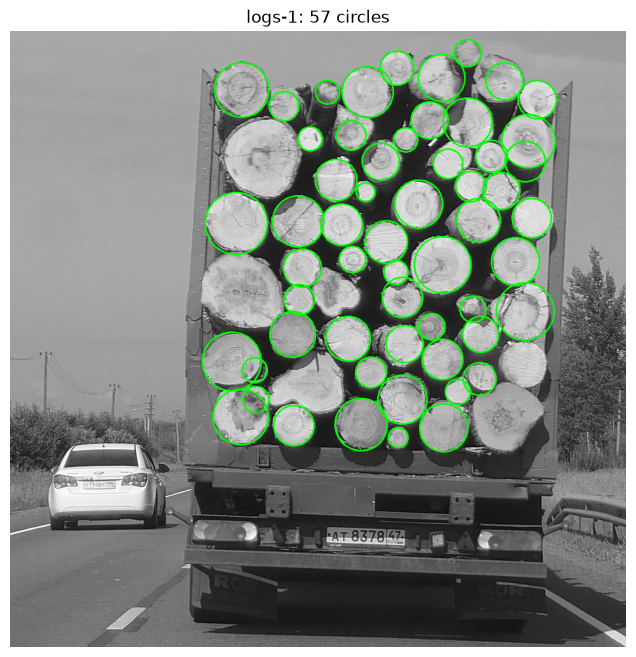

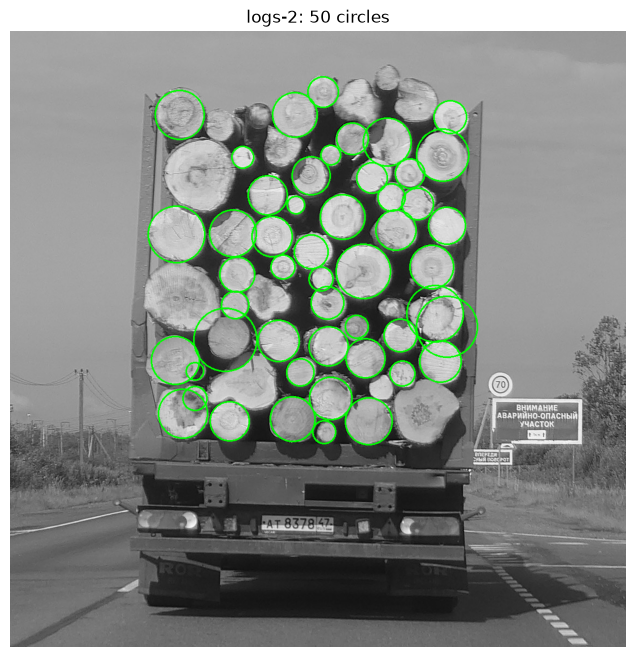

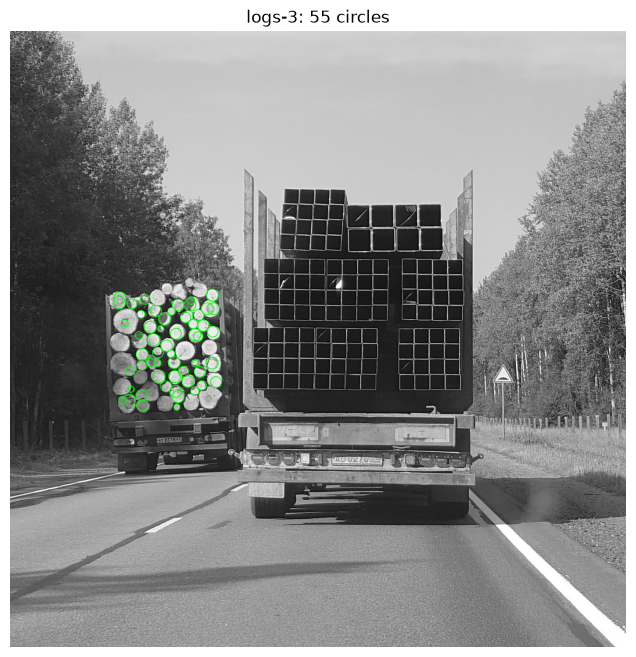

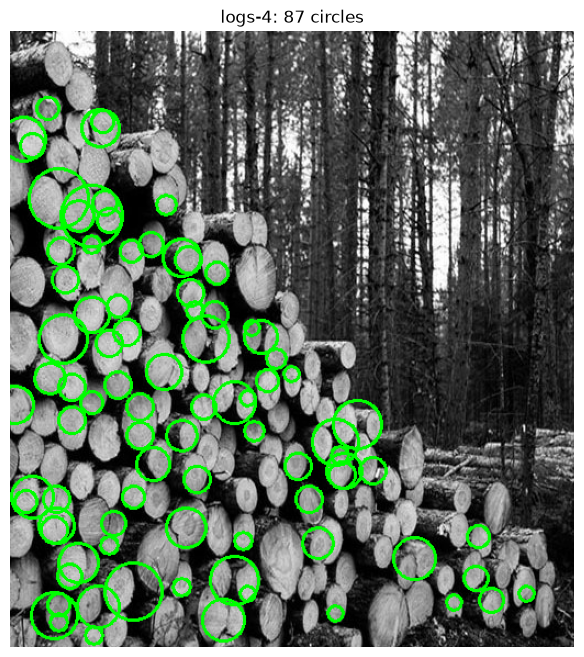

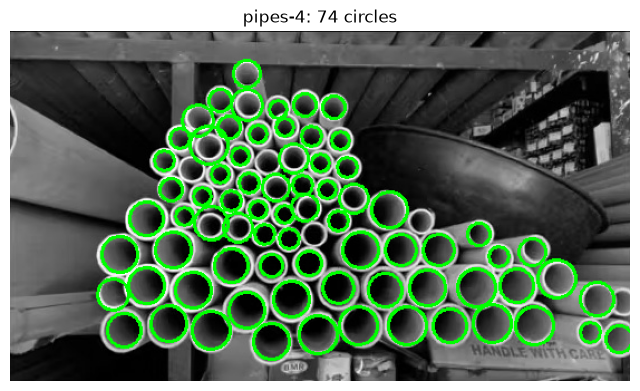

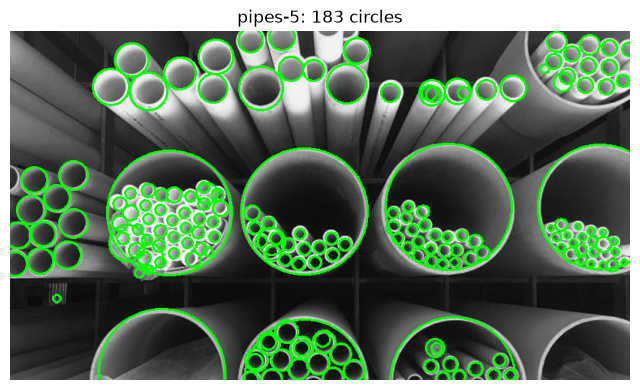

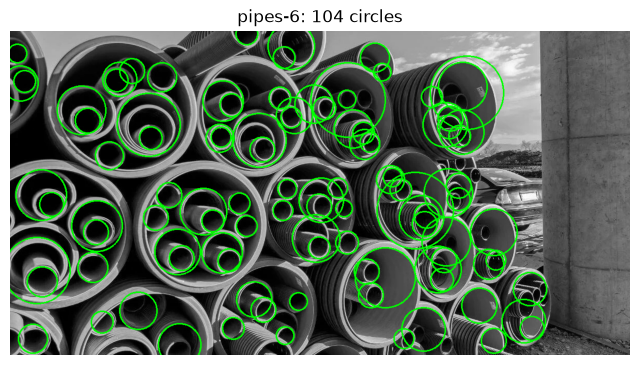

In [153]:
results = {}

for name, img in images.items():

    h, w = img.shape[:2]
    settings = params.get(name, {}).copy()

    if name == "logs-1":
        settings["roi"] = (
            int(w * 0.23),
            int(h * 0.01),
            int(w * 0.90),
            int(h * 0.72)
        )

    elif name == "logs-2":
        settings["roi"] = (
            int(w * 0.23),
            int(h * 0.001),
            int(w * 0.77),
            int(h * 0.72)
        )

    elif name == "logs-3":
        settings["roi"] = (
            int(w * 0.17),
            int(h * 0.42),
            int(w * 0.36),
            int(h * 0.64)
        )

    elif name == "logs-4":
        settings["polygon"] = [
            (0, 0),
            (int(w * 0.15), 0),
            (int(w * 0.33), int(h * 0.30)),
            (int(w * 0.53), int(h * 0.54)),
            (int(w * 0.78), int(h * 0.76)),
            (w - 1, int(h * 0.82)),
            (w - 1, h - 1),
            (0, h - 1)
        ]

    result, count = detect_circles(img, name=name, **settings)

    results[name] = count

    plt.figure(figsize=(8, 8))
    plt.imshow(result)
    plt.title(f"{name}: {count} circles")
    plt.axis("off")
    plt.show()
